# Modelos de LGD y EAD frente a la evidencia comparada

**Pregunta:** ¿Se sostienen para los modelos de C08 y C09 los hallazgos de los estudios comparativos de pérdida dado el incumplimiento y exposición al incumplimiento, un R cuadrado bajo, una ganancia de los modelos no lineales y la necesidad de calibrar, cuando las mismas familias se corren sobre datos cuya verdad se conoce?

- **Nivel:** 3, comparación con métodos publicados
- **Requisitos previos:** los notebooks 03, 05 y 06 de este tema
- **Tiempo de lectura:** unos 50 minutos

## Objetivos

Al terminar este notebook puedes:

- enunciar qué hallaron los estudios comparativos de pérdida dado el incumplimiento y de exposición al incumplimiento, con sus fuentes, y decir cuáles de las familias de modelos que comparan implementa Contraste y cuáles no;
- correr la comparación entre modelos no lineales y lineales sobre una muestra cuya verdad se conoce, con los peldaños del motor y una implementación de referencia de árboles potenciados por gradiente, y leer el R cuadrado y la brecha de calibración de cada uno;
- comprobar, en las seis cohortes de incumplimiento de C08, las afirmaciones sobre el R cuadrado, el logit fraccional frente a MCO y la sensibilidad del modelo beta a su ajuste de extremos;
- ajustar los modelos de EAD de factor, directo y de cambio de utilización sobre líneas generadas en tres niveles de aceleración y compararlos con el contraste retrospectivo propio del motor;
- decir qué no muestran estas comprobaciones, para que un resultado sobre un indicador de castigos y sobre un generador no se lea como un resultado sobre un banco.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 matplotlib==3.11.2 scikit-learn==1.9.1
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti.

In [1]:
# Poner el código del caso en la ruta de importación, importar los paquetes e imprimir sus versiones
import importlib.metadata as md
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.lgd_ead import lgd_models as lm
from riskvalidation.validation import lgd_ead as tests
from sklearn.ensemble import GradientBoostingRegressor

ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.cases.c09 import estimators, generator
from pipeline.cases.c09 import models as ead_models

for name in ("riskvalidation", "numpy", "scikit-learn", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
scikit-learn 1.9.1
matplotlib 3.11.2


## Datos

Evidencia versionada y dos generadores. Las seis variantes por cohorte de incumplimiento del caso C08 (`data/derived/C08/dc-2003-06.json` a `dc-2020-23.json`) guardan los puntajes fuera de muestra temporal de los seis peldaños de LGD sobre los préstamos a pequeñas empresas SBA 7(a), donde la LGD es un indicador de castigos con un sesgo declarado (notebook 01). Las seis variantes por nivel de aceleración del caso C09 (`data/derived/C09/level-0.json` a `level-5.json`) son un generador de líneas de crédito rotativas con un CCF conocido (notebook 02); el notebook lee de ellas el plan de replicaciones y los tramos de utilización, y vuelve a sortear las líneas en tres niveles. Una tercera fuente es una muestra de juguete de LGD generada en el notebook, con una función de media conocida, para la comparación de modelos no lineales y lineales. Dos cautelas enmarcan todo lo que sigue: el objetivo de C08 es un indicador con un sesgo declarado y no una LGD de recuperación, y las líneas de C09 y del juguete son sintéticas, de modo que las comparaciones son sobre los modelos con estos datos y no sobre ningún prestamista.

In [2]:
# Cargar las variantes por cohorte de C08 y los niveles de C09; imprimir las versiones que los hornearon y el plan
COHORTS = ["2003-06", "2007-08", "2009-10", "2011-13", "2014-19", "2020-23"]
derived_dir = ROOT / "data" / "derived"
c08 = {c: json.loads((derived_dir / "C08" / f"dc-{c}.json").read_text(encoding="utf-8")) for c in COHORTS}
c09 = [json.loads((derived_dir / "C09" / f"level-{i}.json").read_text(encoding="utf-8")) for i in range(6)]
generator_doc = json.loads((derived_dir / "C09" / "models-generator.json").read_text(encoding="utf-8"))
plan = generator_doc["fit"]["replications_plan"]
bands = c09[3]["outputs"]["ead_backtest"]["bands"]
baked08 = sorted({v["provenance"]["riskvalidation_version"] for v in c08.values()})
baked09 = sorted({v["provenance"]["riskvalidation_version"] for v in c09})
print("C08:", baked08, "| C09:", baked09)
print("instalado:", rv.__version__, "| tramos de utilización:", bands)
light = {"green": "verde", "amber": "ámbar", "red": "rojo", "not_evaluated": "no evaluada"}

C08: ['1.0.1'] | C09: ['1.0.1']
instalado: 1.0.1 | tramos de utilización: [0.0, 0.2, 0.4, 0.6, 0.8, 1.0, 1.5, 4.0]


## Método

### Paso 1: las cantidades de LGD a comparar

La comparación necesita, para cada cohorte y peldaño, cuatro números que presentó el notebook 03: el R cuadrado, el RMSE, la correlación de rangos de Spearman y la brecha de calibración (indicador sustituto realizado medio menos predicho medio). Con ellos la celda deriva, cohorte por cohorte, las cinco cantidades sobre las que tratan las afirmaciones de la sección siguiente:

1. el rango del R cuadrado entre los peldaños;
2. la ganancia de R cuadrado de los árboles con árboles potenciados sobre el logit fraccional (no lineal frente a lineal), y el peldaño con la mayor correlación de Spearman;
3. la diferencia de R cuadrado y de RMSE entre el logit fraccional y MCO;
4. la correlación de rangos, entre los peldaños de la cohorte, del R cuadrado con la brecha de calibración absoluta (negativa significa que un mayor R cuadrado va con una menor brecha);
5. el rango de la predicción media del peldaño beta sobre los tres ajustes de extremos de `endpoint_sensitivity`, frente a la diferencia entre las brechas de calibración del peldaño beta y del logit fraccional.

Un peldaño que no corrió en una cohorte (el modelo en dos etapas, en tres cohortes, notebook 03) simplemente está ausente de su `rung_comparison`.

In [3]:
# Derivar las cinco cantidades de cada una de las seis cohortes desde las comparaciones de peldaños versionadas
short = {"L1-ols": "OLS", "L2-fractional-logit": "logit fraccional", "L3-beta": "beta", "L4-hurdle": "dos etapas",
         "L5-gradient-boosted": "árboles potenciados", "L6-tobit": "Tobit"}
derived = {}
for c in COHORTS:
    rc = {r["rung_id"]: r for r in c08[c]["outputs"]["rung_comparison"]}
    r2 = np.array([r["r2"] for r in rc.values()])
    gap = np.array([abs(r["calibration_gap"]) for r in rc.values()])
    means = [e["mean_predicted"]["value"] for e in c08[c]["outputs"]["endpoint_sensitivity"]]
    frac, ols, beta = rc["L2-fractional-logit"], rc["L1-ols"], rc["L3-beta"]
    derived[c] = {
        "r2_min": r2.min(), "r2_max": r2.max(), "gain": rc["L5-gradient-boosted"]["r2"] - frac["r2"],
        "best_sp": max(rc, key=lambda k: rc[k]["spearman"]),
        "d_r2": frac["r2"] - ols["r2"], "d_rmse": frac["rmse"] - ols["rmse"],
        "rho": np.corrcoef(np.argsort(np.argsort(r2)), np.argsort(np.argsort(gap)))[0, 1],
        "eps_range": max(means) - min(means), "gap_diff": abs(beta["calibration_gap"] - frac["calibration_gap"]),
    }
print("cohorte  R2 mín  R2 máx  potenciado-fraccional  mejor Spearman")
for c, d in derived.items():
    print(f"{c:8s} {d['r2_min']:7.4f} {d['r2_max']:7.4f} {d['gain']:+22.4f} {short[d['best_sp']]:>22s}")

cohorte  R2 mín  R2 máx  potenciado-fraccional  mejor Spearman
2003-06   0.1990  0.2497                +0.0355    árboles potenciados
2007-08   0.1767  0.2435                +0.0422    árboles potenciados
2009-10   0.1083  0.1793                +0.0437    árboles potenciados
2011-13   0.0975  0.1632                +0.0526    árboles potenciados
2014-19   0.1350  0.1925                +0.0576    árboles potenciados
2020-23   0.1558  0.2105                +0.0379    árboles potenciados


### Paso 2: las familias de EAD sobre líneas generadas

Para la exposición al incumplimiento, el contraste retrospectivo del motor (notebook 06) da, para cada modelo, la mayor brecha relativa absoluta por tramo de utilización, con un umbral verde en 0,10 y uno rojo en 0,25. Tres familias de modelos importan para la literatura: los modelos de factor (el CCF aplicado al monto no utilizado, aquí el diseño de horizonte fijo con piso y tope), el modelo directo de EAD (un logit fraccional de EAD sobre el límite) y el modelo de cambio de utilización. La celda sortea tres replicaciones de desarrollo y tres de prueba de 50.000 facilidades con las semillas del plan versionado, las realiza en los niveles de aceleración 0, 3 y 5, ajusta los ocho modelos del caso sobre las líneas de desarrollo de cada nivel y evalúa las tres familias sobre las líneas de prueba con `ead_backtest_by_band`. También lee cuántas líneas tuvo que recortar el ajuste directo sobre el límite.

In [4]:
# Ajustar los modelos de EAD en tres niveles con líneas de desarrollo y contrastar tres familias en líneas de prueba
dev_seeds, test_seeds = plan["development_seeds"][:3], plan["test_seeds"][:3]
population = {seed: generator.draw_population(seed, 50_000) for seed in dev_seeds + test_seeds}
designs = ("fixed-horizon", "cohort", "variable-horizon")
families = ("ccf-fixed-horizon-floor-cap", "direct-ead", "utilisation-change")
ead = {}
for level in (0, 3, 5):
    lines = {s: generator.realise(population[s], level) for s in dev_seeds + test_seeds}
    dev = {d: estimators.join([estimators.observe(lines[s], d) for s in dev_seeds]) for d in designs}
    test = estimators.join([estimators.observe(lines[s], "fixed-horizon") for s in test_seeds])
    fits = ead_models.fit_models(dev)
    util = test.drawn_ref / test.limit_ref
    for family in families:
        predicted = ead_models.predict(fits[family], test)
        ead[(level, family)] = tests.ead_backtest_by_band(predicted, test.ead, util, np.array(bands), model_id=family)
    ead[(level, "clipped")] = fits["direct-ead"].ead_fit.extras["n_clipped_above"]
print(f"{'nivel':>6s} " + " ".join(f"{f[:22]:>24s}" for f in families) + f" {'directo: recortadas':>26s}")
for level in (0, 3, 5):
    cells = " ".join(f"{ead[(level, f)].metric:8.4f} {light[ead[(level, f)].light.value]:>15s}" for f in families)
    print(f"{level:6d} {cells} {ead[(level, 'clipped')]:26,d}")

 nivel   ccf-fixed-horizon-floo               direct-ead       utilisation-change        directo: recortadas
     0   0.0466           verde   0.5661            rojo   0.1966           ámbar                      1,709
     3   0.0252           verde   0.5659            rojo   0.2288           ámbar                      2,052
     5   0.0167           verde   0.5658            rojo   0.2486           ámbar                      2,359


## Comparación

Las afirmaciones de abajo son las del dosier de investigación de este producto sobre modelos de riesgo de crédito (sus secciones de LGD y de EAD y CCF), que las registra a partir de los resúmenes y de las búsquedas de los artículos y no de sus textos completos. Léanse como la posición de la literatura tal como la encontró la investigación, y las comprobaciones como lo que muestran, junto a ella, los resultados versionados de Contraste.

| Fuente | Qué encontró, según se registra | En Contraste |
|---|---|---|
| Loterman, Brown, Martens, Mues y Baesens (2012) | 24 técnicas sobre seis conjuntos reales de pérdidas de bancos: R cuadrado promedio entre 4% y 43%; las técnicas no lineales significativamente mejores que las lineales; los modelos de dos etapas con una parte lineal y una no lineal casi igual de buenos, con una parte lineal legible | la escalera del notebook 03 sobre C08: cinco peldaños paramétricos en el motor y árboles con árboles potenciados en el flujo de procesamiento; se comprueba abajo |
| Qi y Zhao (2011) | seis métodos: los métodos no paramétricos superan a los paramétricos dentro y fuera de muestra cuando se controla el sobreajuste; la regresión de respuesta fraccional tiene una pequeña ventaja sobre MCO; la beta y la gaussiana inversa son muy sensibles al ajuste pequeño de los valores en 0 o 1 | `fit_fractional_logit`, `fit_beta` con su sensibilidad informada, árboles con árboles potenciados; se comprueba abajo |
| Leow y Mues (2012); Tong, Mues y Thomas (2013) | un modelo de dos etapas (probabilidad de pérdida, luego severidad); un modelo gamma ajustado en cero para la LGD hipotecaria | `fit_hurdle` (logit y luego logit fraccional; la severidad gamma no está implementada) |
| Ospina y Ferrari (2012) | regresión beta inflada en cero o uno | no está en el motor |
| Bellotti y Crook (2012) | modelos de LGD con variables macroeconómicas para tarjetas de crédito | no está en la escalera; C08 no usa ninguna trayectoria macro |
| Tong, Mues, Brown y Thomas (2016) | para la EAD de tarjetas, el CCF tiene una distribución bimodal acotada entre 0 y 1; se comparan modelos de EAD directos (una mezcla gamma ajustada en cero) con tres variantes de CCF y un modelo de cambio de utilización, y el modelo gamma ajustado en cero es más exacto en calibración | `fit_direct_ead` (un logit fraccional; el motor declara que la mezcla gamma ajustada en cero no está en esta versión), los diseños de CCF, `fit_utilisation_change`; se comprueba abajo |
| Leow y Crook (2013) | el saldo modelado directamente con un modelo de supervivencia para el sobrelímite y modelos de panel; R cuadrado de 0.49 sobre la vida del préstamo y 0.55 al incumplir | no está en el motor |

La investigación extrae una conclusión que enmarca las comprobaciones: el R cuadrado de la LGD es bajo en todos los estudios, así que una afirmación de una gran ganancia de exactitud debe ponerse frente a esos rangos, y la evaluación debe incluir la calibración (LGD media por segmento y en el tiempo), no solo el R cuadrado o el RMSE. Para la EAD agrega que el contraste retrospectivo se hace en moneda por tramo de utilización, y que el diseño de fecha de referencia es una elección de modelo importante que debe justificarse (notebook 05).

### El R cuadrado es bajo, como en los estudios comparados

La primera comprobación es el rango. Los estudios comparados informan un R cuadrado promedio entre 4% y 43% sobre técnicas y conjuntos de datos. La celda imprime el rango del R cuadrado sobre todos los peldaños y cohortes de C08 y dónde queda en ese intervalo, y dibuja el R cuadrado de cada peldaño por cohorte.

R cuadrado sobre 36 puntajes peldaño-cohorte: mínimo 0.0975 | máximo 0.2497


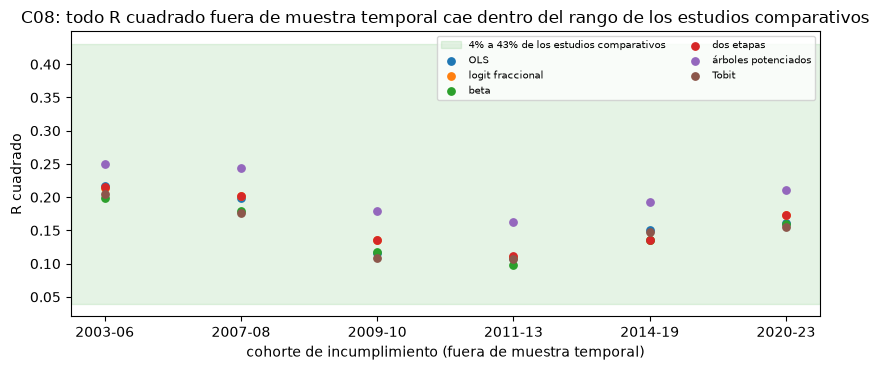

In [5]:
# Dibujar el R cuadrado fuera de muestra temporal de cada peldaño y cohorte contra el rango de los estudios
points = [(i, r["r2"], r["rung_id"]) for i, c in enumerate(COHORTS) for r in c08[c]["outputs"]["rung_comparison"]]
all_r2 = [p[1] for p in points]
print(f"R cuadrado sobre {len(all_r2)} puntajes peldaño-cohorte: mínimo {min(all_r2):.4f} | máximo {max(all_r2):.4f}")
fig, ax = plt.subplots(figsize=(8.4, 3.8))
ax.axhspan(0.04, 0.43, color="tab:green", alpha=0.12, label="4% a 43% de los estudios comparativos")
for rung_id, label in short.items():
    mine = [p for p in points if p[2] == rung_id]
    ax.scatter([p[0] for p in mine], [p[1] for p in mine], label=label, s=28)
ax.set_xticks(range(len(COHORTS)))
ax.set_xticklabels(COHORTS)
ax.set_xlabel("cohorte de incumplimiento (fuera de muestra temporal)")
ax.set_ylabel("R cuadrado")
ax.set_title("C08: todo R cuadrado fuera de muestra temporal cae dentro del rango de los estudios comparativos")
ax.legend(fontsize=7, ncol=2)
fig.tight_layout()
plt.show()

Los treinta y seis puntos quedan dentro de la banda verde, y ninguno se acerca a su extremo superior: el mejor R cuadrado fuera de muestra temporal es cerca de 0,25 frente a un techo de 0,43 en los estudios, y el peor cerca de 0,10 frente a un piso de 0,04. Dentro de una cohorte los peldaños quedan juntos y uno, el de árboles potenciados, va por encima del resto en todas las cohortes, un patrón que examinan los pasos siguientes. Las cohortes importan tanto como los peldaños: la nube baja de 2003-06 a 2011-13 y se recupera después, de modo que un único R cuadrado oculta cuánto cambia la época de los incumplimientos la habilidad aparente de un modelo.

### No lineal frente a lineal, corrido sobre una verdad conocida

La afirmación comparada es que los métodos no lineales superan a los lineales cuando se controla el sobreajuste. En C08 los préstamos reales no se versionan, así que la comparación no puede reajustarse ahí; las puntuaciones versionadas se comprueban en las secciones siguientes. Para correr la afirmación misma el notebook genera una muestra cuya función de media se conoce y tiene una interacción que un modelo de efectos principales no puede representar, ajusta los peldaños lineales y de dos etapas del motor en una mitad y los evalúa en la otra. La primera celda ajusta y evalúa los peldaños del motor.

In [6]:
# Generar una muestra con una interacción conocida y ajustar los peldaños lineales del motor en la primera mitad
rng = np.random.default_rng(20261028)
n = 8000
z = rng.normal(size=(n, 3))
mu = 1 / (1 + np.exp(-(0.2 + 1.3 * z[:, 0] * z[:, 1] - 0.9 * (z[:, 2] > 0.3))))
body = rng.beta(mu * 4.0, (1 - mu) * 4.0)
y = np.where(rng.random(n) < 0.15, 0.0, np.where(rng.random(n) < 0.08, 1.0, body))
X = np.column_stack([np.ones(n), z])
train, hold = slice(0, n // 2), slice(n // 2, n)
rungs = {"OLS": lm.fit_ols(X[train], y[train]), "logit fraccional": lm.fit_fractional_logit(X[train], y[train]),
         "dos etapas": lm.fit_hurdle(X[train], y[train])}
pred = {name: lm.predict_lgd(fit, X[hold]) for name, fit in rungs.items()}
print(f"LGD realizada media fuera de la muestra de ajuste: {y[hold].mean():.4f}")
for name, p in pred.items():
    r2 = 1 - np.sum((y[hold] - p) ** 2) / np.sum((y[hold] - y[hold].mean()) ** 2)
    print(f"{name:20s} R cuadrado {r2:7.4f} | brecha de calibración {y[hold].mean() - p.mean():+.4f}")

LGD realizada media fuera de la muestra de ajuste: 0.4371
OLS                  R cuadrado  0.0256 | brecha de calibración +0.0090
logit fraccional     R cuadrado  0.0255 | brecha de calibración +0.0090
dos etapas           R cuadrado  0.0260 | brecha de calibración +0.0089


La implementación de referencia es el `GradientBoostingRegressor` de scikit-learn, fijado en `notebooks/requirements.txt`: 200 árboles de profundidad 3 sobre la misma mitad, evaluados en la otra con las mismas dos medidas. Representa a la familia no lineal de los estudios (el motor mismo mantiene su peldaño de árboles potenciados en el flujo de procesamiento, no en el paquete).

In [7]:
# Ajustar árboles potenciados por gradiente como referencia y evaluarlos igual que los peldaños del motor
boost = GradientBoostingRegressor(n_estimators=200, max_depth=3, learning_rate=0.05, random_state=0)
boost.fit(z[train], y[train])
pred["árboles potenciados (referencia)"] = np.clip(boost.predict(z[hold]), 0.0, 1.0)
scores = {}
for name, p in pred.items():
    r2 = 1 - np.sum((y[hold] - p) ** 2) / np.sum((y[hold] - y[hold].mean()) ** 2)
    scores[name] = (r2, y[hold].mean() - p.mean())
    print(f"{name:34s} R cuadrado {r2:7.4f} | brecha de calibración {scores[name][1]:+.4f}")

OLS                                R cuadrado  0.0256 | brecha de calibración +0.0090
logit fraccional                   R cuadrado  0.0255 | brecha de calibración +0.0090
dos etapas                         R cuadrado  0.0260 | brecha de calibración +0.0089
árboles potenciados (referencia)   R cuadrado  0.2077 | brecha de calibración +0.0054


La celda siguiente dibuja las dos puntuaciones lado a lado, discriminación a la izquierda y calibración a la derecha, para los tres peldaños del motor y la referencia.

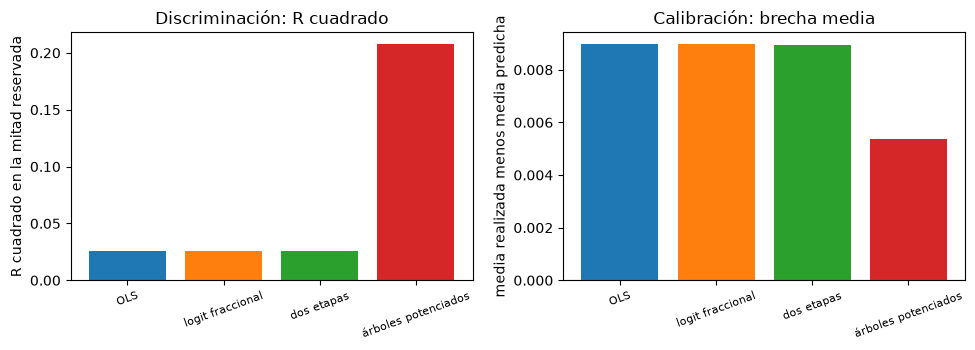

In [8]:
# Dibujar el R cuadrado y la brecha de calibración de cada modelo en la mitad fuera de la muestra de ajuste
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.6))
names = list(scores)
left.bar(range(len(names)), [scores[k][0] for k in names], color=["tab:blue", "tab:orange", "tab:green", "tab:red"])
right.bar(range(len(names)), [scores[k][1] for k in names], color=["tab:blue", "tab:orange", "tab:green", "tab:red"])
ylabels = ("R cuadrado en la mitad reservada", "media realizada menos media predicha")
for ax, ylabel in zip((left, right), ylabels):
    ax.set_xticks(range(len(names)))
    ax.set_xticklabels([k.split(" (")[0] for k in names], rotation=20, fontsize=8)
    ax.set_ylabel(ylabel)
right.axhline(0.0, color="grey", linewidth=0.8)
left.set_title("Discriminación: R cuadrado")
right.set_title("Calibración: brecha media")
fig.tight_layout()
plt.show()

Sobre una verdad que contiene una interacción el modelo no lineal gana en R cuadrado por un margen amplio, que es la afirmación comparada en su forma limpia; los tres peldaños lineales y de dos etapas empatan y quedan bajos porque ninguno puede representar el producto de las dos primeras covariables. El panel derecho es el recordatorio de la conclusión de los estudios: las ganancias de R cuadrado no dicen nada sobre el nivel, y cada modelo tiene su propia brecha de calibración, pequeña aquí para los cuatro. En C08 la brecha no es pequeña, por lo que las cohortes versionadas se examinan a continuación.

Las pruebas propias del motor juzgan los mismos cuatro modelos en la mitad reservada. `lgd_calibration_by_segment` es la prueba t pareada de la brecha media y `lgd_discrimination` la correlación de Spearman contra umbrales fijos, las dos pruebas que el notebook 06 calcula a mano y que informan las filas versionadas de C08; la celda imprime su valor p, su correlación y sus semáforos.

In [9]:
# Correr las pruebas de calibración y discriminación del motor sobre los cuatro modelos de la mitad reservada
for name, p in pred.items():
    seg = tests.lgd_calibration_by_segment(y[hold], p, segment=name)
    order = tests.lgd_discrimination(y[hold], p, segment=name)
    left = f"{name:34s} calibración p={seg.p_value:.3g} {light[seg.light.value]:8s}"
    print(left, f"| Spearman {order.statistic:.4f} {light[order.light.value]}")

OLS                                calibración p=0.1 verde    | Spearman 0.1563 ámbar
logit fraccional                   calibración p=0.0996 verde    | Spearman 0.1563 ámbar
dos etapas                         calibración p=0.101 verde    | Spearman 0.1573 ámbar
árboles potenciados (referencia)   calibración p=0.275 verde    | Spearman 0.4078 verde


### Dos peldaños no lineales más: un bosque aleatorio y una red neuronal

Bellotti, Brigo, Gambetti y Vrins (2021) compararon veinte técnicas sobre datos de recuperación a nivel de registro y hallaron a
los conjuntos de reglas (Cubist), los procesos gaussianos y los bosques aleatorios por delante de los modelos lineales. Por eso la
escalera de LGD del producto va más allá de un solo modelo potenciado con dos familias más de aprendizaje automático, como
peldaños L7 y L8 (`pipeline.cases.c08.ml_benchmark`): el
`RandomForestRegressor` de scikit-learn con divisiones por error cuadrático y hojas de al menos 30 préstamos, y un `MLPRegressor`
con dos capas ocultas de 32 y 16 unidades y detención temprana sobre un décimo del tramo de entrenamiento, ambos fijados antes de
ver cualquier cohorte de prueba. La celda siguiente ajusta los dos peldaños, con la configuración del producto, sobre la misma mitad
de la muestra con interacción conocida que aprendieron arriba los árboles potenciados, y los evalúa sobre la misma mitad
reservada.

In [ ]:
# Ajustar los dos peldaños nuevos del pipeline, el bosque aleatorio y la red neuronal, sobre la misma mitad y evaluarlos
import warnings

from sklearn.exceptions import ConvergenceWarning

from pipeline.cases.c08 import ml_benchmark as ml

forest = ml.fit_forest(z[train], y[train], 7)
with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=ConvergenceWarning)
    network = ml.fit_network(z[train], y[train], 7)
pred["random forest (L7)"] = ml.predict(forest, z[hold])
pred["neural network (L8)"] = ml.predict(network, z[hold])
epochs_label = "épocas de la red"
gap_label = "brecha de calibración"
print(f"{epochs_label}: {network.n_iter_} / {network.max_iter}")
for name in ("fractional logit", "boosted trees (reference)", "random forest (L7)", "neural network (L8)"):
    p = pred[name]
    r2 = 1 - np.sum((y[hold] - p) ** 2) / np.sum((y[hold] - y[hold].mean()) ** 2)
    rmse = np.sqrt(np.mean((y[hold] - p) ** 2))
    print(f"{name:28s} R2 {r2:.4f} | RMSE {rmse:.4f} | {gap_label} {y[hold].mean() - p.mean():+.4f}")


Sobre la interacción conocida la red neuronal es la mejor de las cuatro: un R cuadrado de 0,2249 y un RMSE de 0,3074 contra
0,2077 y 0,3108 de los árboles potenciados, mientras el bosque aleatorio, con 0,1709, queda entre los árboles potenciados y el
logit fraccional (0,0255). La red se detiene al final de su presupuesto de épocas, que la celda imprime, así que no convergió en el
sentido del optimizador; el producto mantiene ese presupuesto porque la pérdida de la mitad reservada ya no mejoraba. La pregunta
para el producto es si este orden sobrevive en los castigos reales, cohorte por cohorte y fuera de tiempo. La figura siguiente lee
la comparación versionada de las seis cohortes de incumplimiento del caso C08.

In [ ]:
# Dibujar el RMSE fuera de tiempo de cada cohorte: el mejor peldaño lineal, los árboles potenciados y los dos nuevos
linear = ("L1-ols", "L2-fractional-logit", "L3-beta", "L4-hurdle", "L6-tobit")
series = {"best linear": [], "L5-gradient-boosted": [], "L7-random-forest": [], "L8-neural-network": []}
outcomes = []
for c in COHORTS:
    rows = c08[c]["outputs"]["rung_comparison"]
    rc = {r["rung_id"]: r["rmse"] for r in rows}
    series["best linear"].append(min(rc[k] for k in linear if k in rc))
    for k in ("L5-gradient-boosted", "L7-random-forest", "L8-neural-network"):
        series[k].append(rc[k])
    outcomes.append(ml.cohort_result(rows))
fig, ax = plt.subplots(figsize=(8.4, 3.8))
for k, v in series.items():
    ax.plot(COHORTS, v, marker="o", label=k)
ax.set_xlabel("cohorte de incumplimiento de prueba")
ax.set_ylabel("RMSE fuera de tiempo de la LGD")
ax.set_title("Los peldaños nuevos frente a los árboles potenciados, cohorte a cohorte")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
for c, o in zip(COHORTS, outcomes):
    print(f"{c}: {o['classical'][0]} {o['classical'][1]:.4f} | {o['ml'][0]} {o['ml'][1]:.4f} | {o['gain']:+.4f}")
wins = sum(o["ml_wins"] for o in outcomes)
wins_label = "cohortes donde el mejor peldaño nuevo gana a los seis anteriores"
print(f"{wins_label}: {wins} / {len(COHORTS)} -> {ml.verdict(wins, len(COHORTS))}")


Las cuatro líneas corren casi superpuestas en todas las cohortes: el RMSE fuera de tiempo se mueve de cerca de 0,275 a 0,33
según la cohorte, y la distancia entre la mejor y la peor de las cuatro opciones lineales y no lineales es de unas milésimas. El
mejor de los dos peldaños nuevos gana a los árboles potenciados en dos cohortes, 2003-06 por 0,0001 y 2014-19 por 0,0005, y pierde
en las otras cuatro, así que la hipótesis fijada antes de la corrida, que los peldaños nuevos mejoran a los seis anteriores en al menos dos tercios de las
cohortes, queda refutada por la regla del propio producto. En una muestra con una interacción fuerte la red gana; en los registros
de castigos, cuya señal es débil, la flexibilidad adicional no compra nada que los árboles potenciados no tuvieran ya.

### No lineal frente a lineal, y fraccional frente a MCO

Dos afirmaciones para comprobar sobre las cantidades derivadas del paso 1. Los métodos no paramétricos (no lineales) superan a los paramétricos cuando se controla el sobreajuste: aquí los árboles con árboles potenciados frente al logit fraccional, por ganancia de R cuadrado y por el peldaño con la mayor correlación de Spearman en cada cohorte. Y la regresión de respuesta fraccional tiene una pequeña ventaja sobre MCO: aquí la diferencia de R cuadrado y de RMSE entre ambos, que la celda cuenta sobre las cohortes. Una cautela para leerlas: los árboles con árboles potenciados tienen 200 árboles de profundidad 6 ajustados una vez con datos hasta el corte, y las cohortes son fuera de tiempo, así que el sobreajuste está controlado en el sentido del diseño de la prueba; el notebook no ajusta nada.

In [10]:
# Contar las cohortes donde se cumple cada afirmación, desde las cantidades derivadas en el paso 1
gains = [d["gain"] for d in derived.values()]
print(f"ganancia de R cuadrado de árboles potenciados sobre logit fraccional: {min(gains):+.4f} a {max(gains):+.4f}")
print(f"positiva en {sum(g > 0 for g in gains)} de {len(COHORTS)} cohortes")
best = {c: short[d["best_sp"]] for c, d in derived.items()}
print("peldaño con la mayor correlación de Spearman:", sorted(set(best.values())))
d_r2 = [d["d_r2"] for d in derived.values()]
d_rmse = [d["d_rmse"] for d in derived.values()]
print(f"logit fraccional menos MCO, R cuadrado: {['%+.4f' % x for x in d_r2]}")
better = sum(x > 0 for x in d_r2)
lower = sum(x < 0 for x in d_rmse)
print(f"R cuadrado mayor en {better} de {len(COHORTS)} | RMSE menor en {lower} de {len(COHORTS)}")
print(f"mayor diferencia absoluta: R cuadrado {max(map(abs, d_r2)):.4f}, RMSE {max(map(abs, d_rmse)):.4f}")

ganancia de R cuadrado de árboles potenciados sobre logit fraccional: +0.0355 a +0.0576
positiva en 6 de 6 cohortes
peldaño con la mayor correlación de Spearman: ['árboles potenciados']
logit fraccional menos MCO, R cuadrado: ['-0.0023', '+0.0029', '+0.0192', '+0.0016', '-0.0150', '+0.0118']
R cuadrado mayor en 4 de 6 | RMSE menor en 4 de 6
mayor diferencia absoluta: R cuadrado 0.0192, RMSE 0.0034


### El modelo beta y su ajuste de extremos

Qi y Zhao encontraron que los modelos beta (y gaussiano inverso) son muy sensibles al número pequeño que se usa para mover los valores en 0 y 1 al interior del intervalo abierto. C08 informa esa sensibilidad para el peldaño beta en cada cohorte (`endpoint_sensitivity`). Para juzgar si la sensibilidad importa, la celda compara el rango de la predicción media sobre los tres ajustes con la diferencia de brecha de calibración entre el peldaño beta y el logit fraccional, que es el tamaño de la elección de familia de modelo. Cuando lo primero es mayor, la elección del ajuste mueve el nivel del modelo más que la elección entre esas dos familias.

In [11]:
# Reajustar el peldaño beta con tres valores de epsilon sobre la muestra con una interacción conocida
print(f"media realizada fuera de la muestra de ajuste: {y[hold].mean():.4f}")
for eps in (0.0001, 0.001, 0.01):
    fit = lm.fit_beta(X[train], y[train], eps)
    mean_p = lm.predict_lgd(fit, X[hold]).mean()
    print(f"epsilon={eps:<7} predicción media {mean_p:.4f} | brecha {y[hold].mean() - mean_p:+.4f}")

media realizada fuera de la muestra de ajuste: 0.4371
epsilon=0.0001  predicción media 0.4270 | brecha +0.0102
epsilon=0.001   predicción media 0.4312 | brecha +0.0059
epsilon=0.01    predicción media 0.4375 | brecha -0.0004


En la muestra cuya verdad se conoce el nivel del peldaño beta se mueve con el número pequeño, como hallaron los estudios: su brecha va de +0,0102 a -0,0004 sobre los tres valores, un rango de cerca de 0,0105, tan grande como la brecha de +0,0090 de los peldaños lineales. Las cohortes versionadas de C08 dan la misma comparación sobre el indicador real, en la celda siguiente.

In [12]:
# Comparar el rango de la predicción media del peldaño beta sobre epsilon con la diferencia de brecha
print(f"{'cohorte':8s} {'rango sobre epsilon':>24s} {'diferencia de brecha':>24s} {'epsilon mayor':>16s}")
bigger = 0
for c, d in derived.items():
    bigger += d["eps_range"] > d["gap_diff"]
    print(f"{c:8s} {d['eps_range']:24.4f} {d['gap_diff']:24.4f} {d['eps_range'] > d['gap_diff']!s:>16}")
print(f"cohortes donde el ajuste de extremos mueve más el nivel que la familia: {bigger} de {len(COHORTS)}")

cohorte       rango sobre epsilon     diferencia de brecha    epsilon mayor
2003-06                    0.0057                   0.0123            False
2007-08                    0.0166                   0.0145             True
2009-10                    0.0234                   0.0142             True
2011-13                    0.0147                   0.0067             True
2014-19                    0.0016                   0.0026            False
2020-23                    0.0100                   0.0011             True
cohortes donde el ajuste de extremos mueve más el nivel que la familia: 4 de 6


### Calibración y R cuadrado

La conclusión de la investigación es que la evaluación debe incluir la calibración y no solo el R cuadrado. Entre los peldaños de una misma cohorte, ¿un mayor R cuadrado va con una menor brecha de calibración? La celda imprime la correlación de rangos calculada en el paso 1 (negativa significa que sí) y si el peldaño con el mayor R cuadrado es también el de menor brecha absoluta en cada cohorte.

In [13]:
# Imprimir la correlación de rangos del R cuadrado con la brecha y si el mayor R cuadrado es la menor brecha
same = 0
for c in COHORTS:
    rc = {r["rung_id"]: r for r in c08[c]["outputs"]["rung_comparison"]}
    top_r2 = max(rc, key=lambda k: rc[k]["r2"])
    top_gap = min(rc, key=lambda k: abs(rc[k]["calibration_gap"]))
    same += top_r2 == top_gap
    print(f"{c:8s} correlación de rangos {derived[c]['rho']:+.3f} | {short[top_r2]:>20s} | {short[top_gap]:>20s}")
print(f"el peldaño con el mayor R cuadrado tiene también la menor brecha en {same} de {len(COHORTS)}")

2003-06  correlación de rangos -0.886 |  árboles potenciados |                  OLS
2007-08  correlación de rangos -0.771 |  árboles potenciados |  árboles potenciados
2009-10  correlación de rangos -0.714 |  árboles potenciados |     logit fraccional
2011-13  correlación de rangos -0.200 |  árboles potenciados |           dos etapas
2014-19  correlación de rangos +0.371 |  árboles potenciados |                  OLS
2020-23  correlación de rangos -0.829 |  árboles potenciados |  árboles potenciados
el peldaño con el mayor R cuadrado tiene también la menor brecha en 2 de 6


### EAD: modelos de factor frente a un modelo directo

Para la exposición al incumplimiento, Tong et al. (2016) comparan modelos de EAD directos con variantes de CCF y un modelo de cambio de utilización sobre datos de tarjetas del Reino Unido y encuentran el modelo directo gamma ajustado en cero más exacto en calibración. Contraste no puede reproducir esa comparación, porque su modelo directo es un logit fraccional y no una mezcla gamma ajustada en cero (el docstring del motor lo dice). Lo que puede mostrar son las mismas tres familias sobre el generador C09 mediante el contraste retrospectivo del motor: la tabla del paso 2 y una figura de la métrica por nivel.

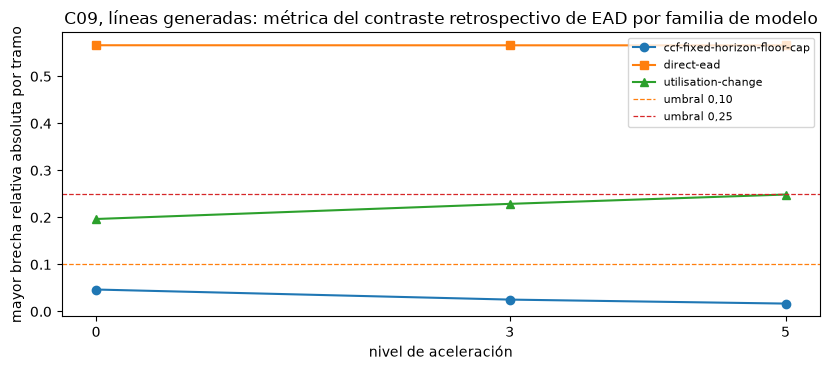

nivel 0: modelo directo, peor tramo [1.5, 4.0) -0.5661
nivel 3: modelo directo, peor tramo [1.5, 4.0) -0.5659
nivel 5: modelo directo, peor tramo [1.5, 4.0) -0.5658


In [14]:
# Dibujar la métrica del contraste retrospectivo de las tres familias de EAD en tres niveles, con los umbrales
fig, ax = plt.subplots(figsize=(8.4, 3.8))
for family, marker in zip(families, ("o", "s", "^")):
    ax.plot([0, 3, 5], [ead[(level, family)].metric for level in (0, 3, 5)], marker=marker, label=family)
ax.axhline(0.10, color="tab:orange", linestyle="--", linewidth=0.9, label="umbral 0,10")
ax.axhline(0.25, color="tab:red", linestyle="--", linewidth=0.9, label="umbral 0,25")
ax.set_xticks([0, 3, 5])
ax.set_xlabel("nivel de aceleración")
ax.set_ylabel("mayor brecha relativa absoluta por tramo")
ax.set_title("C09, líneas generadas: métrica del contraste retrospectivo de EAD por familia de modelo")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
for level in (0, 3, 5):
    worst = max(ead[(level, "direct-ead")].extras["bands"], key=lambda band: abs(band["relative_gap"] or 0.0))
    edge = f"[{worst['lower']}, {worst['upper']})"
    print(f"nivel {level}: modelo directo, peor tramo {edge} {worst['relative_gap']:+.4f}")

El modelo de factor queda bajo el umbral verde en los tres niveles, el de cambio de utilización sobre él y subiendo con la aceleración, y el modelo directo muy por encima del umbral rojo en todos los niveles, con su peor tramo siempre el mismo, las líneas sobre su límite, impreso bajo la figura. El orden es estable porque sale de cómo se construye cada modelo y no de la aceleración: el modelo directo no puede superar el límite, el de cambio de utilización no está acotado y sobrelee las líneas cercanas al límite, y el de factor aplica una parte al monto no utilizado que tenga cada línea. Esta es la pregunta de la comparación puesta a los modelos del motor, con un veredicto que depende de la métrica y de los datos.

## Resultados

**Respuesta:** En su mayor parte sí, con dos límites. En una muestra con una interacción conocida los árboles potenciados alcanzan un R cuadrado fuera de la muestra de ajuste de 0,2077 frente a 0,0255 del logit fraccional y 0,0256 de MCO, la ganancia no lineal de los estudios en su forma limpia. En las seis cohortes de C08 los 36 puntajes de R cuadrado peldaño-cohorte van de 0,0975 a 0,2497, dentro del 4% a 43% de los estudios, y los árboles potenciados superan al logit fraccional entre 0,0355 y 0,0576 en 6 de 6 cohortes; el primer límite es que el peldaño con el mayor R cuadrado tiene la menor brecha de calibración en solo 2 de 6. El segundo es la EAD: en líneas generadas el modelo de factor queda en verde (0,0466 en el nivel 0, 0,0252 en el nivel 3), el de cambio de utilización en ámbar (0,1966 a 0,2486) y el directo en rojo (0,5658 a 0,5661).

- **El R cuadrado es bajo y queda dentro del rango comparado.** Sobre los 36 puntajes peldaño-cohorte de C08 el R cuadrado va de 0,0975 a 0,2497, dentro del intervalo de 4% a 43% que informan los estudios.
- **Lo no lineal supera a lo lineal.** En la muestra de interacción conocida los árboles potenciados puntúan 0,2077 y los peldaños lineales y de dos etapas 0,0255, 0,0256 y 0,0260; en C08 los árboles potenciados ganan de 0,0355 a 0,0576 de R cuadrado sobre el logit fraccional en las seis cohortes y tienen la mayor correlación de Spearman en las seis, con la cautela de que el objetivo es un indicador con un sesgo declarado.
- **Las pruebas del motor coinciden sobre la verdad conocida.** En la mitad reservada el semáforo de calibración es verde para los cuatro modelos (valores p de 0,0996 a 0,275) mientras la correlación de Spearman es 0,1563 (ámbar) para MCO y el logit fraccional, 0,1573 para el peldaño de dos etapas y 0,4078 (verde) para los árboles potenciados; la brecha del peldaño beta va de +0,0102 a -0,0004 cuando epsilon pasa de 0,0001 a 0,01.
- **La ventaja del logit fraccional sobre MCO es pequeña y mixta.** Tiene el mayor R cuadrado en 4 de 6 cohortes y el menor RMSE en 4 de 6, y la mayor diferencia es de 0,0192 de R cuadrado y 0,0034 de RMSE, frente a la ganancia de 0,0355 a 0,0576 de los árboles potenciados.
- **El ajuste de extremos del peldaño beta importa.** El rango de su predicción media sobre los tres ajustes va de 0,0016 a 0,0234, y supera la diferencia de brecha de calibración entre el peldaño beta y el logit fraccional en 4 de las 6 cohortes: en ellas, la elección del número pequeño mueve el nivel más que la elección entre esas dos familias.
- **El R cuadrado y la calibración van juntos solo en parte.** Entre los peldaños de una cohorte, la correlación de rangos entre el R cuadrado y la brecha absoluta está entre -0,886 y -0,714 en tres cohortes y es -0,829 en 2020-23, -0,200 en 2011-13 y +0,371 en 2014-19; el mayor R cuadrado coincide con la menor brecha absoluta solo en 2007-08 y 2020-23. La calibración debe leerse por derecho propio.
- **En EAD, el modelo de factor pasa y el logit fraccional directo falla.** En los niveles 0, 3 y 5 el modelo de factor puntúa 0,0466, 0,0252 y 0,0167 (verde), el de cambio de utilización 0,1966, 0,2288 y 0,2486 (ámbar, creciente con la aceleración) y el directo 0,5661, 0,5659 y 0,5658 (rojo), siempre en el tramo de 1,5 a 4,0 veces el límite, tras recortar 1.709, 2.052 y 2.359 líneas de entrenamiento.
- **Lo que no se reproduce.** El modelo directo gamma con ceros de Tong y otros (2016) no está en el motor, así que el hallazgo de que calibra mejor que los modelos de factor no se confirma ni se contradice; tampoco están implementados el beta inflado en cero o uno, los modelos condicionados por macro ni los de supervivencia.

Lo que estas comprobaciones no muestran: usan un indicador de castigos con un sesgo declarado, una muestra de juguete y un generador sintético cuya verdad está definida a doce meses, de modo que dicen cómo se comportan los modelos con estos datos y no los ordenan para ningún banco. Las afirmaciones comparadas son las de la investigación tal como las registró desde resúmenes, no una revisión de los artículos completos.

Los dos peldaños de aprendizaje automático se comportan como dice el estudio comparativo solo donde la señal es
fuerte: en la muestra con interacción conocida la red neuronal alcanza un R cuadrado de 0,2249 contra 0,2077 de los árboles
potenciados, mientras en las seis cohortes de castigos el mejor peldaño nuevo gana a los árboles potenciados en 2 de 6, por a lo
sumo 0,0005 de RMSE, y la hipótesis queda refutada.

## Resumen

- La literatura comparada sobre LGD halla un R cuadrado bajo en todas partes, una ventaja de los métodos no lineales, una leve de la respuesta fraccional sobre MCO, y una fuerte sensibilidad del modelo beta a su ajuste de extremos; para EAD compara modelos directos con modelos de factor y de cambio de utilización. Contraste implementa MCO, logit fraccional, beta, un modelo de dos etapas con logit fraccional y Tobit para LGD, árboles potenciados en su flujo de procesamiento, y los modelos de factor, directo (logit fraccional) y de cambio de utilización para EAD; no implementa los modelos gamma con ceros, beta inflada, condicionados por macro ni de supervivencia.
- Corridos sobre una muestra con una interacción conocida, los árboles potenciados superan a los peldaños lineales y de dos etapas por un amplio margen de R cuadrado; en las seis cohortes de C08 el R cuadrado queda dentro del rango de los estudios, los árboles potenciados tienen el mayor R cuadrado en todas las cohortes, la ventaja del logit fraccional sobre MCO es pequeña y mixta, y en cuatro de las seis cohortes el nivel del peldaño beta se mueve más con su ajuste de extremos que con la elección entre él y el logit fraccional.
- El peldaño con el mayor R cuadrado es el mejor calibrado solo en algunas cohortes, así que la calibración debe juzgarse junto al R cuadrado.
- En líneas generadas de C09 los modelos de factor pasan el contraste retrospectivo del motor en todos los niveles, el de cambio de utilización queda en ámbar o peor, y el logit fraccional directo falla en el mismo tramo en todos los niveles. Esto no reproduce a Tong y otros (2016), cuyo modelo directo es otro.
- Todo esto trata de un indicador de castigos y de generadores sintéticos, de modo que es una afirmación sobre los modelos con estos datos.

**Qué probar después.** Lee la calibración por tramo versionada de una cohorte junto al R cuadrado de cada peldaño y anota qué peldaño llevarías a un comité de modelos, y qué evidencia pedirías todavía. Este tema no tiene notebook de nivel 4: ninguna afirmación del SDD descansa aún en los casos de LGD y EAD.

- El bosque aleatorio y la red neuronal no mejoran la LGD fuera de tiempo de los castigos: el mejor de los dos gana a los árboles potenciados en 2 de 6 cohortes por a lo sumo 0,0005 de RMSE.

## Referencias

- Loterman, G., Brown, I., Martens, D., Mues, C. y Baesens, B. (2012), Benchmarking regression algorithms for loss given default modeling, International Journal of Forecasting 28(1):161-170. https://doi.org/10.1016/j.ijforecast.2011.01.006
- Qi, M. y Zhao, X. (2011), Comparison of modeling methods for loss given default, Journal of Banking and Finance 35(11):2842-2855. https://doi.org/10.1016/j.jbankfin.2011.03.011
- Leow, M. y Mues, C. (2012), Predicting loss given default (LGD) for residential mortgage loans: a two-stage model and empirical evidence for UK bank data, International Journal of Forecasting 28(1):183-195. https://doi.org/10.1016/j.ijforecast.2011.01.010
- Tong, E. N. C., Mues, C. y Thomas, L. (2013), A zero-adjusted gamma model for mortgage loan loss given default, International Journal of Forecasting 29(4):548-562. https://doi.org/10.1016/j.ijforecast.2013.03.003
- Ospina, R. y Ferrari, S. L. P. (2012), A general class of zero-or-one inflated beta regression models, Computational Statistics and Data Analysis 56(6):1609-1623. https://doi.org/10.1016/j.csda.2011.10.005
- Bellotti, T. y Crook, J. (2012), Loss given default models incorporating macroeconomic variables for credit cards, International Journal of Forecasting 28(1):171-182. https://doi.org/10.1016/j.ijforecast.2010.08.005
- Tong, E. N. C., Mues, C., Brown, I. y Thomas, L. C. (2016), Exposure at default models with and without the credit conversion factor, European Journal of Operational Research 252(3):910-920. https://doi.org/10.1016/j.ejor.2016.01.054
- Leow, M. y Crook, J. (2013), Estimation of credit card exposure at default (EAD), documento de trabajo, University of Edinburgh Credit Research Centre (según el dosier de investigación; leído en las pp. 1 a 5).
- BCBS, Basel Framework, CRE32. https://www.bis.org/committees/bcbs/basel-framework/standard/cre/32/inforce/2023-01-01/published/2020-03-27
- BCBS (2017), Basel III: Finalising post-crisis reforms (d424). https://www.bis.org/bcbs/publ/d424.htm
- El dosier de investigación de este producto sobre modelos de riesgo de crédito (secciones de LGD y de EAD y CCF), que registra los hallazgos de arriba a partir de resúmenes y búsquedas, y la documentación del motor de `fit_direct_ead` (versión 0.8.1).
- Este repositorio: `docs/design/SDD.md` (casos C08 y C09) y `data/derived/C08/`, `data/derived/C09/`.

- Bellotti, A., Brigo, D., Gambetti, P. y Vrins, F. (2021), Forecasting recovery rates on non-performing loans with machine learning, International Journal of Forecasting 37(1), 428-444, https://doi.org/10.1016/j.ijforecast.2020.06.009